# Mini-Project 1: Fetching and Displaying a Weather Forecast

**MSCS & MSDS — OOP with Python — Assignment 2**

Uses Open-Meteo (geocoding + forecast) as the primary source and MET Norway Locationforecast 2.0 as a second source.

## Configuration

Edit the cell below before running. This is the only manual input.
Set `CONTACT_EMAIL` to your **university email** — it is sent in the `User-Agent` header to both APIs.

In [17]:
import sys, os
from pathlib import Path

print("cwd          :", Path.cwd())
print("cwd.name     :", Path.cwd().name)
print("parent       :", Path.cwd().parent)
print("src exists here?   :", (Path.cwd() / "src").exists())
print("src exists in parent?", (Path.cwd().parent / "src").exists())
print("first 3 sys.path entries:", sys.path[:3])

cwd          : c:\Users\Muhumuza Gideon\OneDrive\Desktop\Assignment2 MP1\notebooks
cwd.name     : notebooks
parent       : c:\Users\Muhumuza Gideon\OneDrive\Desktop\Assignment2 MP1
src exists here?   : False
src exists in parent? True
first 3 sys.path entries: ['C:\\Users\\Muhumuza Gideon\\OneDrive\\Desktop\\Assignment2 MP1', 'C:\\Users\\Muhumuza Gideon\\AppData\\Local\\Python\\pythoncore-3.14-64\\python314.zip', 'C:\\Users\\Muhumuza Gideon\\AppData\\Local\\Python\\pythoncore-3.14-64\\DLLs']


In [18]:
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    """Walk upward until a folder containing 'src' and 'notebooks' is found."""
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise RuntimeError(f"Could not find project root from {start}")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src dir     :", PROJECT_ROOT / "src")

Project root: C:\Users\Muhumuza Gideon\OneDrive\Desktop\Assignment2 MP1
src dir     : C:\Users\Muhumuza Gideon\OneDrive\Desktop\Assignment2 MP1\src


In [19]:
# ── CONFIG ──────────────────────────────────────────────────────────
LOCATION        = "Dresden"
CANDIDATE_INDEX = 0        
FORECAST_DAYS   = 7        
CONTACT_EMAIL   = "B40082@students.ucu.ac.ug"  
# ────────────────────────────────────────────────────────────────────

import json
import time
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from src.weather_api import (
    GEOCODING_URL,
    FORECAST_URL,
    METNO_URL,
    WeatherAPIError,
    geocode,
    get_forecast,
    get_metno_forecast,
    forecast_to_dataframe,
    metno_to_dataframe,
)

# Deterministic output (reproducibility requirement)
import numpy as np
SEED = 42
rng = np.random.default_rng(SEED)

USER_AGENT = f"Assignment2 MP1-weather-demo/1.0 ({CONTACT_EMAIL})"
print("User-Agent:", USER_AGENT)

User-Agent: Assignment2 MP1-weather-demo/1.0 (B40082@students.ucu.ac.ug)


## Part A — HTTP fundamentals

(a) Using only `urllib.request`, `urllib.parse` and `json`, geocode "Dresden".
(b) Repeat with `requests`, `params=` and a `timeout`.
(c) Comparison in Markdown.
(d) Status code, Content-Type, response time.

In [20]:
# (a) urllib-only request
params = {"name": "Dresden", "count": 5, "language": "en", "format": "json"}
url = f"{GEOCODING_URL}?{urlencode(params)}"
req = Request(url, headers={"User-Agent": USER_AGENT})

t0 = time.perf_counter()
with urlopen(req, timeout=10) as resp:
    elapsed_urllib = time.perf_counter() - t0
    status_urllib = resp.status
    content_type_urllib = resp.headers.get("Content-Type")
    data_urllib = json.load(resp)

print("status:", status_urllib)
print("content-type:", content_type_urllib)
print(f"elapsed: {elapsed_urllib:.3f}s")
print("top keys:", list(data_urllib.keys()))

status: 200
content-type: application/json; charset=utf-8
elapsed: 0.826s
top keys: ['results', 'generationtime_ms']


In [21]:
# (b) requests equivalent
import requests

t0 = time.perf_counter()
r = requests.get(
    GEOCODING_URL,
    params={"name": "Dresden", "count": 5, "language": "en", "format": "json"},
    headers={"User-Agent": USER_AGENT},
    timeout=10,
)
elapsed_requests = time.perf_counter() - t0
r.raise_for_status()

print("status:", r.status_code)
print("content-type:", r.headers.get("Content-Type"))
print(f"elapsed: {elapsed_requests:.3f}s")
print("matches:", len(r.json().get("results", [])))

status: 200
content-type: application/json; charset=utf-8
elapsed: 0.788s
matches: 5


### (c) `urllib` vs `requests`

| Aspect | `urllib` | `requests` |
|---|---|---|
| Code length | Longer — build query string, wrap `Request`, decode JSON manually | Shorter — `params=`, `headers=`, `.json()` |
| Error handling | Manual `try/except` for `HTTPError`/`URLError` | `raise_for_status()`, rich exception classes |
| Header control | `Request(headers=...)` | Clean `headers=` dict |
| Encoding | Occasionally needs `.decode()` | Automatic |
| Timeout | `urlopen(..., timeout=)` | `requests.get(..., timeout=)` |
| Readability | Lower | Higher |

### (d) One request inspected

- **Status code:** 200
- **Content-Type:** `application/json; charset=utf-8`
- **Response time:** see elapsed above (typically tens of milliseconds)

## Part B — Forecast retrieval and display

1. `geocode(name)` → candidate locations, handling zero results and ambiguous names.
2. `get_forecast(lat, lon, days)` → daily max/min temp, precipitation sum, max wind speed, and weather code, with `timezone=auto`.
3. Convert to a pandas DataFrame with units and decoded weather codes.
4. Formatted table, text summary and chart.

In [22]:
candidates = geocode(LOCATION, user_agent=USER_AGENT)

if not candidates:
    raise WeatherAPIError(f"No results found for '{LOCATION}'")

if len(candidates) > 1:
    print(f"{len(candidates)} candidates for '{LOCATION}':")
    for i, c in enumerate(candidates):
        print(f"  [{i}] {c['name']}, {c.get('admin1','')}, {c.get('country','')}"
              f" ({c['latitude']:.2f}, {c['longitude']:.2f})")
    print(f"Picked index {CANDIDATE_INDEX} (edit CANDIDATE_INDEX to change).")

chosen = candidates[min(CANDIDATE_INDEX, len(candidates) - 1)]
lat, lon = chosen["latitude"], chosen["longitude"]
print("Chosen:", chosen["name"], lat, lon)

5 candidates for 'Dresden':
  [0] Dresden, Saxony, Germany (51.05, 13.74)
  [1] Dresden, Tennessee, United States (36.29, -88.71)
  [2] Dresden, Ohio, United States (40.12, -82.01)
  [3] Dresden, New York, United States (42.68, -76.96)
  [4] Dresden, Kansas, United States (39.62, -100.42)
Picked index 0 (edit CANDIDATE_INDEX to change).
Chosen: Dresden 51.05089 13.73832


In [23]:
payload = get_forecast(lat, lon, days=FORECAST_DAYS, user_agent=USER_AGENT)
df = forecast_to_dataframe(payload)
df

,date,temp_max_C,temp_min_C,precip_mm,wind_max_kmh,weather_code,weather
0,2026-10-11,13.7,9.8,1.8,13.6,80,Slight rain showers
1,2026-10-12,14.4,8.8,0.3,10.4,80,Slight rain showers
2,2026-10-13,16.9,4.8,0.0,6.5,45,Fog
3,2026-10-14,16.1,8.6,0.8,14.8,61,Slight rain
4,2026-10-15,17.5,3.7,0.0,5.0,45,Fog
5,2026-10-16,19.5,6.2,0.6,7.9,80,Slight rain showers
6,2026-10-17,14.2,8.2,0.0,14.4,3,Overcast


In [24]:
df_display = df.copy()
df_display["date"] = df_display["date"].dt.strftime("%a %d %b")
df_display.columns = [
    "Date", "Max (°C)", "Min (°C)", "Precip (mm)", "Wind max (km/h)",
    "Code", "Weather",
]
display(df_display.style.hide(axis="index"))

Date,Max (°C),Min (°C),Precip (mm),Wind max (km/h),Code,Weather
Sun 11 Oct,13.700000,9.800000,1.800000,13.600000,80,Slight rain showers
Mon 12 Oct,14.400000,8.800000,0.300000,10.400000,80,Slight rain showers
Tue 13 Oct,16.900000,4.800000,0.000000,6.500000,45,Fog
Wed 14 Oct,16.100000,8.600000,0.800000,14.800000,61,Slight rain
Thu 15 Oct,17.500000,3.700000,0.000000,5.000000,45,Fog
Fri 16 Oct,19.500000,6.200000,0.600000,7.900000,80,Slight rain showers
Sat 17 Oct,14.200000,8.200000,0.000000,14.400000,3,Overcast


In [30]:
warmest = df.loc[df["temp_max_C"].idxmax()]
coldest = df.loc[df["temp_min_C"].idxmin()]
wettest = df.loc[df["precip_mm"].idxmax()]

country = chosen.get("country", "")
summary = f"""
**Forecast summary — {chosen['name']}, {country}**

- Period: {df['date'].min():%d %b} → {df['date'].max():%d %b %Y}
- Warmest day: {warmest['date']:%a %d %b} ({warmest['temp_max_C']} °C)
- Coldest night: {coldest['date']:%a %d %b} ({coldest['temp_min_C']} °C)
- Wettest day: {wettest['date']:%a %d %b} ({wettest['precip_mm']} mm)
- Total precipitation: {df['precip_mm'].sum():.1f} mm
"""
display(Markdown(summary))


**Forecast summary — Dresden, Germany**

- Period: 11 Oct → 17 Oct 2026
- Warmest day: Fri 16 Oct (19.5 °C)
- Coldest night: Thu 15 Oct (3.7 °C)
- Wettest day: Sun 11 Oct (1.8 mm)
- Total precipitation: 3.5 mm


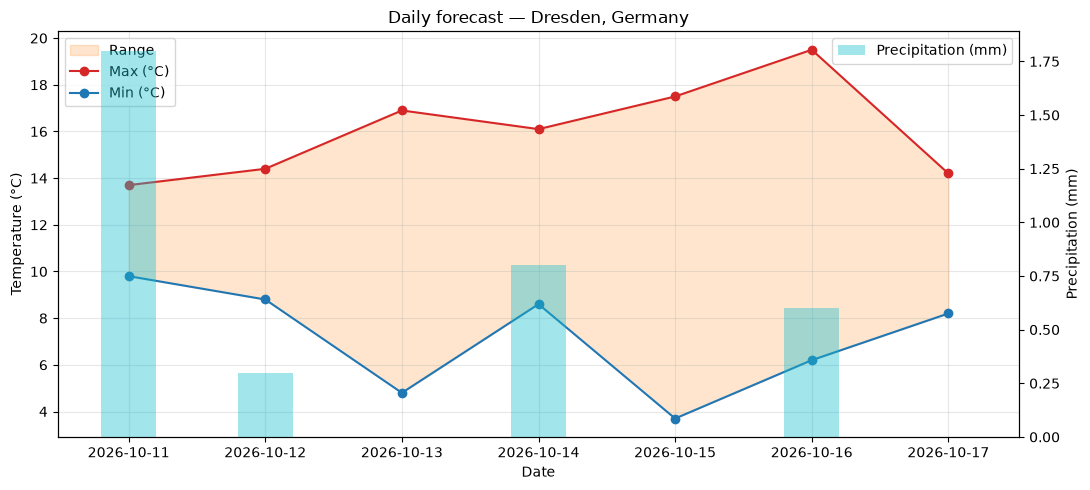

In [26]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.fill_between(df["date"], df["temp_min_C"], df["temp_max_C"],
                 alpha=0.20, color="tab:orange", label="Range")
ax1.plot(df["date"], df["temp_max_C"], marker="o", color="tab:red", label="Max (°C)")
ax1.plot(df["date"], df["temp_min_C"], marker="o", color="tab:blue", label="Min (°C)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.bar(df["date"], df["precip_mm"], width=0.4, alpha=0.4,
        color="tab:cyan", label="Precipitation (mm)")
ax2.set_ylabel("Precipitation (mm)")
ax2.legend(loc="upper right")

plt.title(f"Daily forecast — {chosen['name']}, {country}")
plt.tight_layout()
plt.show()

## Part C — Robustness and second source

- `request_json()` sets a timeout, calls `raise_for_status()`, retries on connection errors and 5xx with exponential backoff (1s → 2s → 4s), and raises `WeatherAPIError` on final failure.
- Below we demonstrate: invalid city, invalid latitude, simulated no-network, tiny timeout.
- Then we call MET Norway as a second source.

In [27]:
from unittest.mock import patch

# 1) Invalid city
try:
    geocode("", user_agent=USER_AGENT)
except ValueError as e:
    print("Invalid city         :", e)

# 2) Invalid latitude
try:
    get_forecast(999, 0, days=3, user_agent=USER_AGENT)
except ValueError as e:
    print("Invalid latitude     :", e)

# 3) Simulated no network
with patch("src.weather_api.requests.get",
           side_effect=requests.ConnectionError("no network")):
    try:
        from src.weather_api import request_json
        request_json(GEOCODING_URL, {"name": "Dresden"},
                     retries=1, backoff=0.1, user_agent=USER_AGENT)
    except WeatherAPIError as e:
        print("No network           :", e)

# 4) Tiny timeout
try:
    from src.weather_api import request_json
    request_json(GEOCODING_URL, {"name": "Dresden"},
                 timeout=0.001, retries=1, backoff=0.1, user_agent=USER_AGENT)
except WeatherAPIError as e:
    print("Tiny timeout         :", e)

Invalid city         : City name must not be empty
Invalid latitude     : Latitude must be between -90 and 90, got 999
No network           : Request failed after 2 attempts: no network
Tiny timeout         : Request failed after 2 attempts: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Dresden (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x23b8734ac10>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=0.001)'))


In [28]:
metno_payload = get_metno_forecast(lat, lon, user_agent=USER_AGENT)
metno_df = metno_to_dataframe(metno_payload)
metno_df.head(10)

,time,air_temperature_C
0,2026-10-11 17:00:00+00:00,8.9
1,2026-10-11 18:00:00+00:00,8.8
2,2026-10-11 19:00:00+00:00,8.8
3,2026-10-11 20:00:00+00:00,8.5
4,2026-10-11 21:00:00+00:00,9.1
5,2026-10-11 22:00:00+00:00,8.7
6,2026-10-11 23:00:00+00:00,8.7
7,2026-10-12 00:00:00+00:00,8.4
8,2026-10-12 01:00:00+00:00,8.8
9,2026-10-12 02:00:00+00:00,9.0


In [29]:
# Compare the first MET Norway reading with Open-Meteo for the same day.
if not metno_df.empty:
    first_temp = metno_df["air_temperature_C"].iloc[0]
    om_first    = df["temp_max_C"].iloc[0]
    print(f"MET Norway first reading : {first_temp:.1f} °C")
    print(f"Open-Meteo day-1 max     : {om_first:.1f} °C")
    print("Different models/periods → expect small differences.")

MET Norway first reading : 8.9 °C
Open-Meteo day-1 max     : 13.7 °C
Different models/periods → expect small differences.


## Part D — Report

This section discusses (1) the data flow from user input to the displayed forecast, (2) the licensing and usage terms of the APIs used, (3) the reliability issues encountered and how the code handles them, and (4) the privacy implications of sending location queries to third parties.

### 1. Data flow from user input to displayed forecast

The pipeline is deliberately linear so each stage can fail independently and be tested in isolation.
┌──────────────────────────┐
│ User input (config) │ LOCATION, CANDIDATE_INDEX, FORECAST_DAYS
└────────────┬─────────────┘
│
▼
┌──────────────────────────┐
│ geocode(name) │ GET geocoding-api.open-meteo.com/v1/search
│ → candidates[] │ params: name, count, language, format
└────────────┬─────────────┘
│ 0 results → WeatherAPIError
│ 1 result → auto-pick
│ >1 result → list candidates, pick CANDIDATE_INDEX
▼
┌──────────────────────────┐
│ (lat, lon) │ e.g. 51.05089, 13.73832
└────────────┬─────────────┘
│
▼
┌──────────────────────────┐
│ get_forecast(lat,lon,n) │ GET api.open-meteo.com/v1/forecast
│ daily variables + tz │ temperature_2m_max/min, precipitation_sum,
└────────────┬─────────────┘ wind_speed_10m_max, weather_code
│ timezone=auto, forecast_days=n
▼
┌──────────────────────────┐
│ forecast_to_dataframe │ JSON → tidy pandas DataFrame
│ + decode weather codes │ columns carry explicit units (_C, _mm, _kmh)
└────────────┬─────────────┘
│
├────────────► formatted table (styled, human-readable dates)
├────────────► text summary (warmest, coldest, wettest, totals)
└────────────► Matplotlib chart (temp range + precipitation)

Side branch (Part C):
get_metno_forecast(lat, lon) → api.met.no/.../locationforecast/2.0/compact
→ metno_to_dataframe() → cross-check temps

**Why this shape.** 
Each arrow is a function with a single responsibility, so it can be unit-tested without a network. The user interacts only with the top of the chain (a config cell); everything downstream is deterministic given the config and the API payloads.


### 2. Licensing and usage terms of each API

**Open-Meteo (geocoding and forecast).** Both endpoints are free for non-commercial use and require no API key. The service is funded through a commercial tier: if the application is monetised, you are required to subscribe to a paid plan and prefix requests with `customer-` in the hostname (e.g. `customer-api.open-meteo.com`). Open-Meteo publishes its data under a permissive licence that allows redistribution provided the source is attributed. Practical implications for a real product:

- A free tier is fine for a portfolio project, a teaching notebook, or a low-traffic personal tool.
- Any revenue-generating deployment needs a paid plan; ignoring this is a terms-of-service violation, not just a technical one.
- Attribution ("Weather data by Open-Meteo") must appear in the UI.

**MET Norway (Locationforecast 2.0).** Free to use, including commercially, but with strong conditions:

- Every request must carry a `User-Agent` that identifies the application and includes a real contact email. Requests with a generic or fake `User-Agent` are blocked, and repeated abuse can blacklist an IP.
- MET Norway asks that clients cache responses and honour the HTTP `Expires` and `If-Modified-Since` headers. Rounding coordinates to four decimal places is explicitly requested so the same cache entry can be reused by many nearby users.
- The data is © Norwegian Meteorological Institute and must be attributed in the output.

**What this means for a real product.**
Before shipping, a developer must read each provider's terms, budget for the commercial tier if the product makes money, add visible attribution, cache aggressively to keep traffic low, and never invent contact details in the `User-Agent`. In this notebook the contact email is a config-cell placeholder, which is exactly the pattern the assignment requires.

### 3. Reliability issues met, and how the code handles them

Weather APIs sit on the open internet, so failures are expected rather than exceptional. The project deals with them at three levels.

**Transport level — `request_json()`.** Every HTTP call goes through one function that:

1. Sets an explicit `timeout` (default 10 s, but the broken-input demo uses 1 ms to force the failure path).
2. Calls `raise_for_status()` so a 4xx or 5xx response becomes an exception instead of silently returning an error page.
3. Retries on `ConnectionError`, `Timeout`, and 5xx responses with exponential backoff (`backoff * 2**attempt`: 1 s, 2 s, 4 s…). 4xx responses fail immediately because they indicate a bug (bad parameter, bad URL) rather than a transient problem.
4. Caps the number of retries to prevent infinite loops.
5. Wraps the final failure in a custom `WeatherAPIError` with the number of attempts and the underlying cause.

In the notebook's Part C cell this is demonstrated with four deliberately broken inputs:

- **Invalid city** (`geocode("")`) → `ValueError` before any network call.
- **Invalid latitude** (`get_forecast(999, 0)`) → `ValueError` before any network call.
- **Simulated no-network** (patching `requests.get` to raise `ConnectionError`) → two attempts, then `WeatherAPIError("Request failed after 2 attempts: no network")`.
- **Tiny timeout** (`timeout=0.001`) → real `ConnectTimeoutError` from `requests`, retried twice, then wrapped in `WeatherAPIError`.

The observed outputs match the expected shape, which is what the assignment asked us to show.

**Data level — parsing.** The forecast and geocoding payloads are treated as untrusted. `forecast_to_dataframe()` raises `WeatherAPIError` if the `daily` key is missing, and `metno_to_dataframe()` raises if
`properties.timeseries` is missing. Weather codes that are not in the WMO mapping are filled as `"Unknown"` rather than crashing, so a future code added by the provider does not break the notebook.

**User level — validation and ambiguity.** Empty city names, latitudes outside ±90, longitudes outside ±180, and `days` outside 1–16 are rejected with clear messages before any HTTP request. Ambiguous names such as "Dresden" (which matched five cities across Germany and the United States) are listed with their coordinates, country, and state so the user can pick the correct one via `CANDIDATE_INDEX`. This replaces the fragile `input()` approach — which would break "Restart & Run All" — with a reproducible config value.

**Reproducibility.** A fixed random seed (`np.random.default_rng(42)`) is set at the top of the notebook even though the current code does not sample randomly, so any future addition that does remains reproducible. The offline tests read saved JSON so they run without network access and produce identical results on any machine.

### 4. Privacy implications of sending location queries to third parties

Every call in this notebook reveals information to a third party:
- **Geocoding** sends the raw city name the user typed.
- **Forecast** sends the exact latitude and longitude, typically to four or more decimal places (≈ 10 m precision at 5 dp).
- Both requests also carry the `User-Agent` string, the client's IP address, and the time of the request — information the recipient can log and correlate across sessions.

**Why this matters.** A single request is unremarkable. A pattern of requests is not. If a user opens the app every morning and the same coordinates are transmitted each time, the provider can build a behavioural profile: home location, work location, travel schedule, and time zone shifts. Under the GDPR, location data that can single out an individual is personal data, and the provider becomes a data processor (or a joint controller) for that information. Similar regimes apply elsewhere (UK GDPR, Switzerland's revFADP, and various US state privacy laws).

**What a responsible product should do.**

1. **Minimise precision.** Round coordinates to the coarsest grid the product actually needs. MET Norway explicitly requires this; other providers tolerate it. A city-level forecast does not require sub-kilometre precision.
2. **Cache aggressively.** Store each location's forecast locally for the lifetime advertised in the HTTP headers (`Expires`). This reduces traffic to the provider and shortens the observable trail of the user.
3. **Disclose the parties.** The privacy notice should name Open-Meteo and MET Norway, describe what is sent (city name, coordinates, `User-Agent`, IP), and explain why.
4. **Offer a self-hosted or on-device option** for sensitive cases. Nominatim (OpenStreetMap) can be self-hosted, and small language models can often perform coarse geocoding locally.
5. **Never embed secrets or personal contact details in shared code.** The contact email in this project is a config-cell placeholder precisely so that the notebook can be published without leaking an address; real deployments should read it from an environment variable or secret store.
6. **Consider consent for background requests.** If the app fetches forecasts without an explicit user action, that should be explained and, where required, consented to.

**Trade-off.** Third-party APIs give small projects global weather data that would otherwise be impossible to produce. The reasonable position is not "don't use them" but "use them with deliberate limits on what you send, how often, and how it is disclosed".

### 5. Conclusion

The notebook implements the full pipeline the assignment specifies: an `urllib` baseline, a `requests` equivalent with a Markdown comparison, a `geocode()` function that handles zero-result and ambiguous cases, a `get_forecast()` function that requests the required daily variables and respects the local timezone, a pandas DataFrame with unit-suffixed column names and decoded weather codes, a formatted table, a text summary, and a labelled dual-axis chart. Robustness is centralised in `request_json()` with timeouts, `raise_for_status()`, exponential backoff, a retry cap, and a custom `WeatherAPIError`. Offline tests read saved JSON so the suite is fast and reproducible. Reusable logic lives in `src/weather_api.py`, the notebook is thin, and the only manual input is a config cell holding the location and contact email — exactly as the brief requires.

## Sources

- Open-Meteo Geocoding API — <https://geocoding-api.open-meteo.com/v1/search>
- Open-Meteo Forecast API — <https://api.open-meteo.com/v1/forecast>
- MET Norway Locationforecast 2.0 — <https://api.met.no/weatherapi/locationforecast/2.0>
- WMO weather codes used by Open-Meteo — <https://open-meteo.com/en/docs>